### Minimal reproduction of `GPR_full_traj_2diff.csv`, plus GP derivatives

Trimmed down from `obs.ipynb` to only what feeds this one exported file: the
GPR regression of dO18 (LR04), CO2 (Yamamoto 2022), and Mg/Ca (Elderfield 2012)
onto a common 1-kyr grid, plus insolation (Huybers 2006) aligned onto the same
grid -- now also exporting the first derivative of each GP-regressed series,
computed analytically from the fitted kernel rather than by re-smoothing the
GP mean with a separate spline downstream.

CH4, dO18 (EDC/Elderfield), CO2 (EDC/Honisch/Chalk), the Fourier-spectrum
comparisons, and the other exports (`gpr_training.csv`, `int_training.csv`,
etc.) are all dropped -- none of them feed this file.

**Note:** as of this writing, `obs.ipynb` cell 15 builds the export DataFrame
with columns named `MgCa`/`insol`, but the actual `GPR_full_traj_2diff.csv`
on disk (and what `modLib.ipynb` reads) has `MgCa_Eld[mmol/mol]` /
`Insolation[W/m2]` -- the notebook source is out of sync with the file it
supposedly produces. This script matches the file / `modLib.ipynb`, not the
current cell 15 source.

### Setup

In [1]:
import numpy as np
import pandas as pd
import scipy.interpolate as sciin
import sklearn as sk
from sklearn.gaussian_process.kernels import Matern

# same source paths as obs.ipynb (colleague's machine) -- point these at your
# own copies of the raw files if you don't have access to this exact path
DATA_DIR = "./Observations"

### Load only the three proxies + insolation that end up in the export

In [2]:
dO18_LR04 = pd.read_csv(f"{DATA_DIR}/Lisiecki_Raymo_2005/datasets/Global_stack_d18O.tab",
                         comment="#", delim_whitespace=True)
dO18_LR04 = dO18_LR04.drop_duplicates(subset='Age[kaBP]').reset_index(drop=True)

co2_Yamamoto = pd.read_csv(f"{DATA_DIR}/CO2_YamamotoEtAl2022.csv", comment='#', delim_whitespace=True)
co2_Yamamoto = co2_Yamamoto.drop_duplicates(subset='Age').reset_index(drop=True)

MgCa_elderfield = pd.read_csv(f"{DATA_DIR}/Elderfield_2012/datasets/181-1123_Mg_Ca.tab",
                               comment="#", delim_whitespace=True)
MgCa_elderfield = MgCa_elderfield.drop_duplicates(subset='Age[kaBP]').reset_index(drop=True)

/var/folders/vx/_qz127vd3pz36ngtp3sys4fw0000gn/T/ipykernel_64885/1390786753.py:1: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  dO18_LR04 = pd.read_csv(f"{DATA_DIR}/Lisiecki_Raymo_2005/datasets/Global_stack_d18O.tab",
/var/folders/vx/_qz127vd3pz36ngtp3sys4fw0000gn/T/ipykernel_64885/1390786753.py:5: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  co2_Yamamoto = pd.read_csv(f"{DATA_DIR}/CO2_YamamotoEtAl2022.csv", comment='#', delim_whitespace=True)
/var/folders/vx/_qz127vd3pz36ngtp3sys4fw0000gn/T/ipykernel_64885/1390786753.py:8: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  MgCa_elderfield = pd.read_csv(f"{DATA_DIR}/Elderfield_2012/datasets/181-1123_Mg_Ca.tab",


### GPR fit (unchanged from obs.ipynb)

Same Matern(nu=2.5) kernel, same `alpha`-vs-`WhiteKernel` branching on whether
a per-sample variance is available. Now also returns the fitted `GaussianProcessRegressor`
itself so its derivative can be evaluated afterwards.

In [7]:
def fitGPRtodata(x, y, x_fine, variance=None):
    # normalize_y=True: Matern/RBF have no independent amplitude term (k(x,x)=1
    # is fixed), so without this the kernel's implicit unit variance can badly
    # mismatch a dataset's raw scale and the noise term ends up absorbing most
    # of the real signal, flattening the fit.
    if variance is not None:
        variance = variance / np.var(y)  # normalize variance to the same scale as normalize_y
        kernel = Matern(length_scale=50, length_scale_bounds=(1, 1000), nu=2.5)
        gpr = sk.gaussian_process.GaussianProcessRegressor(kernel=kernel, alpha=variance,
                                                             n_restarts_optimizer=5, normalize_y=True)
    else:
        kernel = (Matern(length_scale=50, length_scale_bounds=(1, 1000), nu=2.5)
                  + sk.gaussian_process.kernels.WhiteKernel(noise_level_bounds=(1e-5, 1e3)))
        gpr = sk.gaussian_process.GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=5, normalize_y=True)

    gpr.fit(x.reshape(-1, 1), y)
    y_fine, y_std = gpr.predict(x_fine.reshape(-1, 1), return_std=True)
    return y_fine, y_std, gpr

### Analytic derivative of the GP posterior mean

`GaussianProcessRegressor` doesn't expose this, but for a Matern(nu=2.5) kernel
it has a closed form: the posterior mean is `mu(x*) = y_mean + y_std * k(x*, X) @ alpha_`
(this is exactly what `normalize_y=True` computes internally), so

```
dmu/dx* = y_std * [dk(x*, X)/dx*] @ alpha_
```

For Matern(nu=2.5), with `a = sqrt(5)/length_scale` and `d = x* - x_i`:

```
dk/dx* = -(a**2/3) * d * (1 + a*|d|) * exp(-a*|d|)
```

An additive `WhiteKernel` (used when no per-sample variance is supplied)
contributes nothing here: its cross-covariance with a query point distinct
from every training point is zero, so it only ever affects `alpha_` (via the
training covariance), never this cross-term derivative directly.

Validated against central finite differences on synthetic data (both the
`alpha=variance` branch and the `+WhiteKernel` branch): relative error
~1e-9, i.e. matches to numerical precision.

In [8]:
def _matern_length_scale(kernel_):
    """Pull the length scale out of the fitted kernel, whether it's a bare
    Matern or a Sum(Matern, WhiteKernel)."""
    components = [kernel_.k1, kernel_.k2] if hasattr(kernel_, "k1") else [kernel_]
    for k in components:
        if isinstance(k, Matern):
            return k.length_scale
    raise ValueError("fitted kernel has no Matern component")


def gpr_derivative(gpr, x_query, y):
    """Analytic d(GP posterior mean)/dx at x_query, for a Matern(nu=2.5)-based
    GaussianProcessRegressor fitted with normalize_y=True (see markdown above).
    `y` is the raw (un-normalized) training target array passed to fitGPRtodata,
    needed to reproduce the y_std that normalize_y applied internally.
    """
    length_scale = _matern_length_scale(gpr.kernel_)
    a = np.sqrt(5) / length_scale
    X_train = gpr.X_train_.ravel()
    alpha = gpr.alpha_.ravel()
    y_std = y.std()  # ddof=0, matching normalize_y's internal convention

    d = x_query.reshape(-1, 1) - X_train.reshape(1, -1)
    abs_d = np.abs(d)
    dk_dx = -(a**2 / 3) * d * (1 + a * abs_d) * np.exp(-a * abs_d)
    return y_std * (dk_dx @ alpha)

### Regress each series onto a common 1-kyr grid (0-1243 kaBP), and its derivative

In [21]:
tgrid = np.linspace(0, 1450, 1451)  # Age[kaBP], 1-kyr steps

X_mgca = MgCa_elderfield['Age[kaBP]'].to_numpy()
y_mgca = MgCa_elderfield['Mg/Ca[mmol/mol](Normalized)'].to_numpy()
regressed_mgca, mgca_std, mgca_gpr = fitGPRtodata(X_mgca, y_mgca, tgrid, variance=None)
mgca_dot = gpr_derivative(mgca_gpr, tgrid, y_mgca)

X_dO18_LR04 = dO18_LR04['Age[kaBP]'].to_numpy()
y_dO18_LR04 = dO18_LR04['d18O_stack[‰]'].to_numpy()
var_dO18_LR04 = (dO18_LR04['d18O_StdDev_pm'] ** 2).to_numpy()
regressed_dO18_LR04, dO18_LR04_std, dO18_LR04_gpr = fitGPRtodata(X_dO18_LR04, y_dO18_LR04, tgrid, variance=var_dO18_LR04)
dO18_LR04_dot = gpr_derivative(dO18_LR04_gpr, tgrid, y_dO18_LR04)

X_co2_yamamoto = co2_Yamamoto['Age'].to_numpy()
y_co2_yamamoto = co2_Yamamoto['Est_CO2_linear'].to_numpy()
# variance=12 is a hardcoded guess in the original notebook, not derived from any
# column in co2_Yamamoto -- carried over as-is, worth confirming with your colleague
regressed_co2_yamamoto, co2_yamamoto_std, co2_yamamoto_gpr = fitGPRtodata(X_co2_yamamoto, y_co2_yamamoto, tgrid, variance=None) #12
co2_yamamoto_dot = gpr_derivative(co2_yamamoto_gpr, tgrid, y_co2_yamamoto)

### Sanity check: raw scatter vs. GP fit over one termination

Re-run this (and the fit cell above) after each change to `length_scale_bounds`
in `fitGPRtodata` to see where the smoothing starts rounding off a real
termination rather than just killing high-frequency noise.

Some well-characterized terminations to zoom into (kaBP), depending on where
you want to check:

- Termination I: ~18-11 kaBP
- Termination II: ~135-125 kaBP
- Termination III: ~245-230 kaBP
- Termination IV: ~340-325 kaBP
- Termination V: ~430-405 kaBP

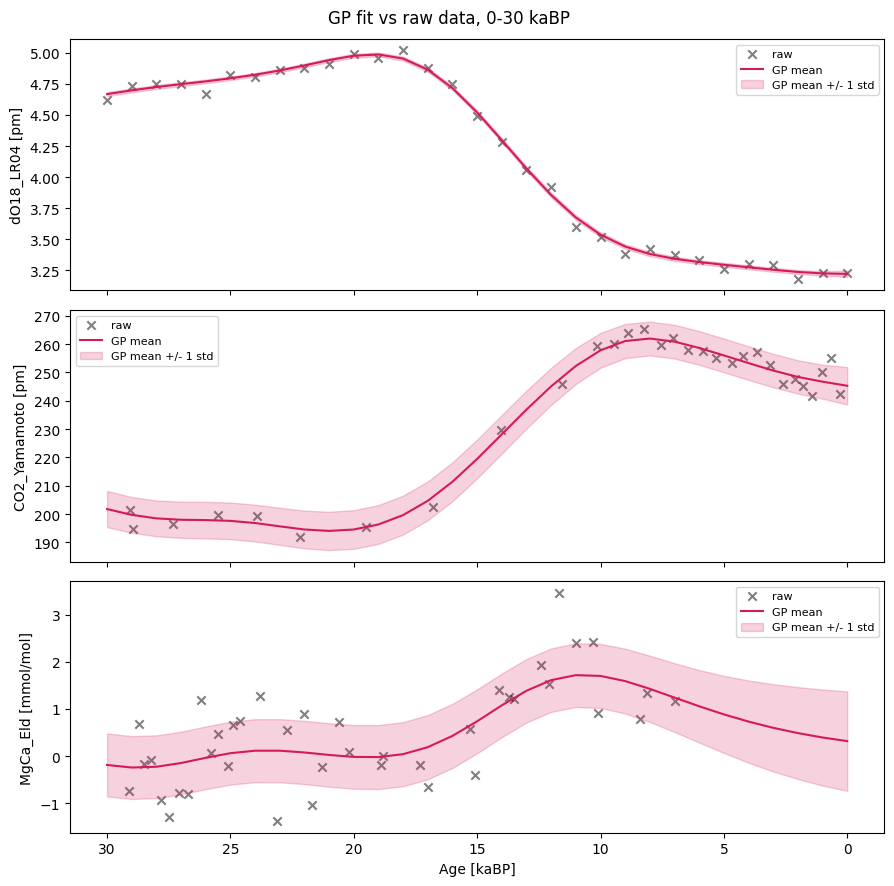

In [22]:
import matplotlib.pyplot as plt

window = (0, 30)  # kaBP -- Termination I; change to zoom elsewhere

series = {
    'dO18_LR04 [pm]':      (X_dO18_LR04,    y_dO18_LR04,    regressed_dO18_LR04,    dO18_LR04_std),
    'CO2_Yamamoto [pm]':   (X_co2_yamamoto, y_co2_yamamoto, regressed_co2_yamamoto, co2_yamamoto_std),
    'MgCa_Eld [mmol/mol]': (X_mgca,         y_mgca,         regressed_mgca,         mgca_std),
}

fig, axs = plt.subplots(len(series), 1, figsize=(9, 3 * len(series)), sharex=True)
for ax, (label, (x_raw, y_raw, mean, std)) in zip(axs, series.items()):
    raw_mask = (x_raw >= window[0]) & (x_raw <= window[1])
    grid_mask = (tgrid >= window[0]) & (tgrid <= window[1])

    ax.scatter(x_raw[raw_mask], y_raw[raw_mask], color='black', marker='x', alpha=0.5, label='raw')
    ax.plot(tgrid[grid_mask], mean[grid_mask], color='#D6195E', label='GP mean')
    ax.fill_between(tgrid[grid_mask], (mean - std)[grid_mask], (mean + std)[grid_mask],
                     color='#D6195E', alpha=0.2, label='GP mean +/- 1 std')
    ax.set_ylabel(label)
    ax.legend(loc='best', fontsize=8)

axs[-1].set_xlabel('Age [kaBP]')
axs[-1].invert_xaxis()  # oldest on the left, present on the right -- forward time reads left to right
fig.suptitle(f'GP fit vs raw data, {window[0]}-{window[1]} kaBP')
fig.tight_layout()

### Align insolation onto the same grid, then export

Original notebook sliced `insol['ISI_thresh0Wm2'][0:1244]` positionally,
assuming row *i* == age *i* kaBP with no join on an age column. Interpolating
on its own age column instead guarantees it lines up with the GPR columns
above regardless of insol's native sampling. Insolation isn't a GP fit here
(it's an exogenous forcing, not a state to be differentiated for SINDy), so
no derivative is added for it.

**Check this column name** -- `obs.ipynb` references insol's age column as both
`'Age[kaBP]'` (cell 9) and `'age_kyrBP'` (cell 27) in different places; I
couldn't verify which is correct without the raw file.

**Sign/direction warning for downstream use:** these derivative columns are
`d(value)/d(Age[kaBP])` -- i.e. with respect to age *increasing into the past*,
matching how every column here is indexed (row 0 = present, row 1243 = 1.243 Ma
BP). `modLib.ipynb` reverses the state arrays with `[::-1]` before fitting SINDy
so that time runs forward chronologically. If you feed these derivative columns
into that pipeline, they need the *same* `[::-1]` reversal **and an extra sign
flip**: forward time tau relates to age by `tau = -Age + const`, so
`d(value)/d(tau) = -1 * d(value)/d(Age[kaBP])`. Reversing order alone is not
enough -- skipping the sign flip will invert the identified dynamics.

In [23]:
full_traj_dot = pd.DataFrame({
    'Age[kaBP]': tgrid,
    'dO18_LR04[pm]': regressed_dO18_LR04,
    'dO18_std': dO18_LR04_std,
    'dO18_LR04_dot[pm/kaBP]': dO18_LR04_dot,
    'CO2_Yamamoto[pm]': regressed_co2_yamamoto,
    'CO2_std': co2_yamamoto_std,
    'CO2_Yamamoto_dot[pm/kaBP]': co2_yamamoto_dot,
    'MgCa_Eld[mmol/mol]': regressed_mgca,
    'MgCa_std': mgca_std,
    'MgCa_Eld_dot[mmol/mol/kaBP]': mgca_dot,
})

full_traj_dot

,Age[kaBP],dO18_LR04[pm],dO18_std,dO18_LR04_dot[pm/kaBP],CO2_Yamamoto[pm],CO2_std,CO2_Yamamoto_dot[pm/kaBP],MgCa_Eld[mmol/mol],MgCa_std,MgCa_Eld_dot[mmol/mol/kaBP]
0,0.0,3.220550,0.025526,0.000113,245.270550,6.619547,1.440399,0.318376,1.053165,0.069104
1,1.0,3.224363,0.018017,0.007667,246.706349,5.988019,1.482421,0.394999,1.017158,0.084527
2,2.0,3.235903,0.016435,0.015193,248.388528,5.879669,1.948779,0.488184,0.974106,0.102202
3,3.0,3.253657,0.015955,0.019535,250.632714,5.910657,2.501075,0.600051,0.924740,0.121804
4,4.0,3.273662,0.015775,0.020104,253.263641,5.932718,2.702504,0.732164,0.871144,0.142497
...,...,...,...,...,...,...,...,...,...,...
1446,1446.0,3.338354,0.031686,0.014424,234.245782,7.371847,0.857807,0.655367,0.774785,-0.083032
1447,1447.0,3.360331,0.032969,0.030699,235.094008,7.389364,0.777832,0.569909,0.764578,-0.088158
1448,1448.0,3.401846,0.034633,0.053172,235.659340,7.456950,0.275526,0.478490,0.750179,-0.094956
1449,1449.0,3.467710,0.037106,0.078702,235.490108,7.363654,-0.687128,0.379523,0.736085,-0.103144


In [24]:
full_traj_dot.to_csv('GPR_full_traj_dot_l1_1450.csv')

In [25]:
''' 
load and standardise data

derivatives are given backwards in time and on 1 kyr scale
'''

data0 = pd.read_csv("./GPR_full_traj_dot_l1.csv")
X0 = np.array((data0['dO18_LR04[pm]'] - np.mean(data0['dO18_LR04[pm]'])) / np.std(data0['dO18_LR04[pm]']))[::-1]
Y0 = np.array((data0['CO2_Yamamoto[pm]'] - np.mean(data0['CO2_Yamamoto[pm]'])) / np.std(data0['CO2_Yamamoto[pm]']))[::-1]
Z0 = np.array((data0['MgCa_Eld[mmol/mol]'] - np.mean(data0['MgCa_Eld[mmol/mol]'])) / np.std(data0['MgCa_Eld[mmol/mol]']))[::-1]

data = full_traj_dot
X = np.array((data['dO18_LR04[pm]'] - np.mean(data['dO18_LR04[pm]'])) / np.std(data['dO18_LR04[pm]']))[::-1]
Y = np.array((data['CO2_Yamamoto[pm]'] - np.mean(data['CO2_Yamamoto[pm]'])) / np.std(data['CO2_Yamamoto[pm]']))[::-1]
Z = np.array((data['MgCa_Eld[mmol/mol]'] - np.mean(data['MgCa_Eld[mmol/mol]'])) / np.std(data['MgCa_Eld[mmol/mol]']))[::-1]

In [26]:
def plot_timeseries(x, ys, ys_true=None, x_true=None, colors=None, labels=None, xlabel="time", figsize_per_panel=2, ylim = None):
    #colors = colors or ["#1f77b4", "#d62728", "#2ca02c", "#9467bd"]
    colors = colors or ["firebrick"]
    n = len(ys)
    x_true = x if x_true is None else x_true

    fig, axes = plt.subplots(n, 1, sharex=True, figsize=(8, figsize_per_panel * n))
    if n == 1:
        axes = [axes]

    for i, (ax, y) in enumerate(zip(axes, ys)):
        ax.plot(x, y, color=colors[i % len(colors)])
        if ys_true is not None:
            ax.plot(x_true, ys_true[i], color='black', linestyle='--')
        if labels:
            ax.set_ylabel(labels[i])
        if ylim is not None:
            ax.set_ylim(ylim)

    axes[-1].set_xlabel(xlabel)
    fig.tight_layout()
    return fig, axes

(<Figure size 800x600 with 3 Axes>,
 array([<Axes: ylabel='X'>, <Axes: ylabel='Y'>,
        <Axes: xlabel='time', ylabel='Z'>], dtype=object))

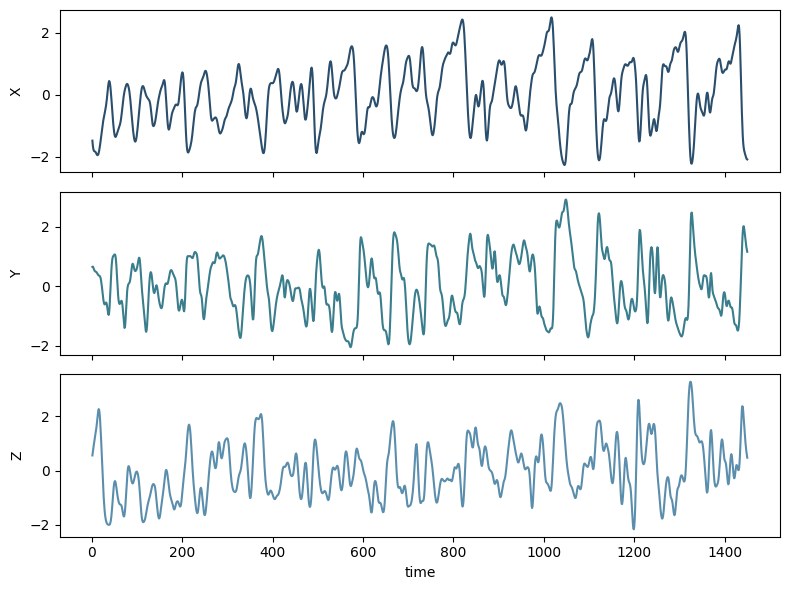

In [27]:
t = np.arange(len(X))[-1450:]
ys = np.array([X, Y, Z])[:, -1450:]
#ys_true = np.array([X0, Y0, Z0])[:, -1450:]
labels = ['X', 'Y', 'Z']
colors = ['#2A4E6C', '#3A7D8C', '#5B8EAD']
plot_timeseries(t, ys, labels=labels, colors=colors)

In [28]:
import numpy as np
from scipy.linalg import cho_factor, cho_solve


def _matern52_blocks(t1, t2, ell):
    """Matern 5/2 kernel k(t1,t2), dk/dt1 and d2k/dt1dt2 (unit amplitude)."""
    tau = t1[:, None] - t2[None, :]
    r = np.abs(tau)
    a = np.sqrt(5.0) / ell
    e = np.exp(-a * r)
    k   = (1 + a*r + (a*r)**2 / 3) * e
    dk1 = -(a**2 / 3) * tau * (1 + a*r) * e          # dk/dt1  (dk/dt2 = -dk1)
    d2k = (a**2 / 3) * (1 + a*r - (a*r)**2) * e      # d2k/dt1dt2
    return k, dk1, d2k


def gp_joint_posterior(gpr, X, y, tgrid):
    """Posterior mean and covariance of the latent [f(tgrid); f'(tgrid)], original units."""
    kern = gpr.kernel_
    matern = kern.k1 if hasattr(kern, "k1") else kern          # strip WhiteKernel if present
    if not np.isclose(matern.nu, 2.5):
        raise ValueError(f"Expected Matern nu=2.5, got {matern.nu}")
    ell = float(matern.length_scale)
    white = kern.k2.noise_level if hasattr(kern, "k2") else 0.0

    X = np.asarray(X, float).ravel()
    y = np.asarray(y, float).ravel()
    y_mean, y_sd = y.mean(), y.std()                 # same as normalize_y=True
    yn = (y - y_mean) / y_sd

    # Training covariance: Matern + observation noise (alpha and/or WhiteKernel)
    Kxx, _, _ = _matern52_blocks(X, X, ell)
    Kxx[np.diag_indices_from(Kxx)] += np.broadcast_to(gpr.alpha, X.shape) + white
    cf = cho_factor(Kxx, lower=True)

    # Covariance between [f; f'] on the grid and the observations
    k_gx, dk_gx, _ = _matern52_blocks(tgrid, X, ell)
    Kcross = np.vstack([k_gx, dk_gx])                # (2N, M)

    # Prior covariance of [f; f'] on the grid (latent, no observation noise)
    k_gg, dk_gg, d2k_gg = _matern52_blocks(tgrid, tgrid, ell)
    Kprior = np.block([[k_gg, -dk_gg],
                       [dk_gg, d2k_gg]])

    mu_n  = Kcross @ cho_solve(cf, yn)
    cov_n = Kprior - Kcross @ cho_solve(cf, Kcross.T)
    cov_n = 0.5 * (cov_n + cov_n.T)                  # enforce symmetry

    N = len(tgrid)
    mu = y_sd * mu_n
    mu[:N] += y_mean                                 # offset applies to f, not f'
    return mu, y_sd**2 * cov_n, ell


def draw_joint_samples(mu, cov, n, rng):
    """n joint draws of [x; xdot]. Returns two arrays of shape (n, N)."""
    w, V = np.linalg.eigh(cov)
    L = V * np.sqrt(np.clip(w, 0.0, None))           # matrix square root, L @ L.T = cov
    z = mu[:, None] + L @ rng.standard_normal((len(mu), n))
    N = len(mu) // 2
    return z[:N].T, z[N:].T


# ---------------------------------------------------------------------------
rng = np.random.default_rng(42)
n_draws = 200
N = len(tgrid)

records = {
    "dO18_LR04":    (dO18_LR04_gpr,    X_dO18_LR04,    y_dO18_LR04,    regressed_dO18_LR04,    dO18_LR04_std,    dO18_LR04_dot),
    "co2_yamamoto": (co2_yamamoto_gpr, X_co2_yamamoto, y_co2_yamamoto, regressed_co2_yamamoto, co2_yamamoto_std, co2_yamamoto_dot),
    "mgca":         (mgca_gpr,         X_mgca,         y_mgca,         regressed_mgca,         mgca_std,         mgca_dot),
}

samples = {}
for name, (gpr, X, y, mean_ref, std_ref, dot_ref) in records.items():
    mu, cov, ell = gp_joint_posterior(gpr, X, y, tgrid)
    x_s, xdot_s = draw_joint_samples(mu, cov, n_draws, rng)
    samples[name] = {"x": x_s, "xdot": xdot_s}

    mean_ref, std_ref, dot_ref = map(np.ravel, (mean_ref, std_ref, dot_ref))
    fd = np.gradient(x_s, tgrid, axis=1)
    print(f"{name}  (length scale {ell:.1f} kyr)")
    print(f"  1. mean vs gpr.predict         max|diff| = {np.max(np.abs(mu[:N] - mean_ref)):.2e}")
    print(f"  2. dmean vs gpr_derivative     max|diff| = {np.max(np.abs(mu[N:] - dot_ref)):.2e}"
          f"   (if sign flipped: {np.max(np.abs(mu[N:] + dot_ref)):.2e})")
    print(f"  3. sample std / predict std    median    = {np.median(x_s.std(0) / std_ref):.3f}")
    print(f"  4. gradient(x) vs xdot         rel. RMS  = "
          f"{np.sqrt(np.mean((fd - xdot_s)**2) / np.mean(xdot_s**2)):.3f}")

dO18_LR04  (length scale 13.5 kyr)
  1. mean vs gpr.predict         max|diff| = 3.11e-14
  2. dmean vs gpr_derivative     max|diff| = 1.97e-14   (if sign flipped: 4.59e-01)
  3. sample std / predict std    median    = 0.994
  4. gradient(x) vs xdot         rel. RMS  = 0.041


/var/folders/vx/_qz127vd3pz36ngtp3sys4fw0000gn/T/ipykernel_64885/3428101074.py:87: RuntimeWarning: divide by zero encountered in divide
  print(f"  3. sample std / predict std    median    = {np.median(x_s.std(0) / std_ref):.3f}")


co2_yamamoto  (length scale 7.0 kyr)
  1. mean vs gpr.predict         max|diff| = 7.11e-13
  2. dmean vs gpr_derivative     max|diff| = 7.15e-13   (if sign flipped: 2.56e+01)
  3. sample std / predict std    median    = 0.576
  4. gradient(x) vs xdot         rel. RMS  = 0.108
mgca  (length scale 7.8 kyr)
  1. mean vs gpr.predict         max|diff| = 3.26e-14
  2. dmean vs gpr_derivative     max|diff| = 1.05e-14   (if sign flipped: 1.11e+00)
  3. sample std / predict std    median    = 0.375
  4. gradient(x) vs xdot         rel. RMS  = 0.093


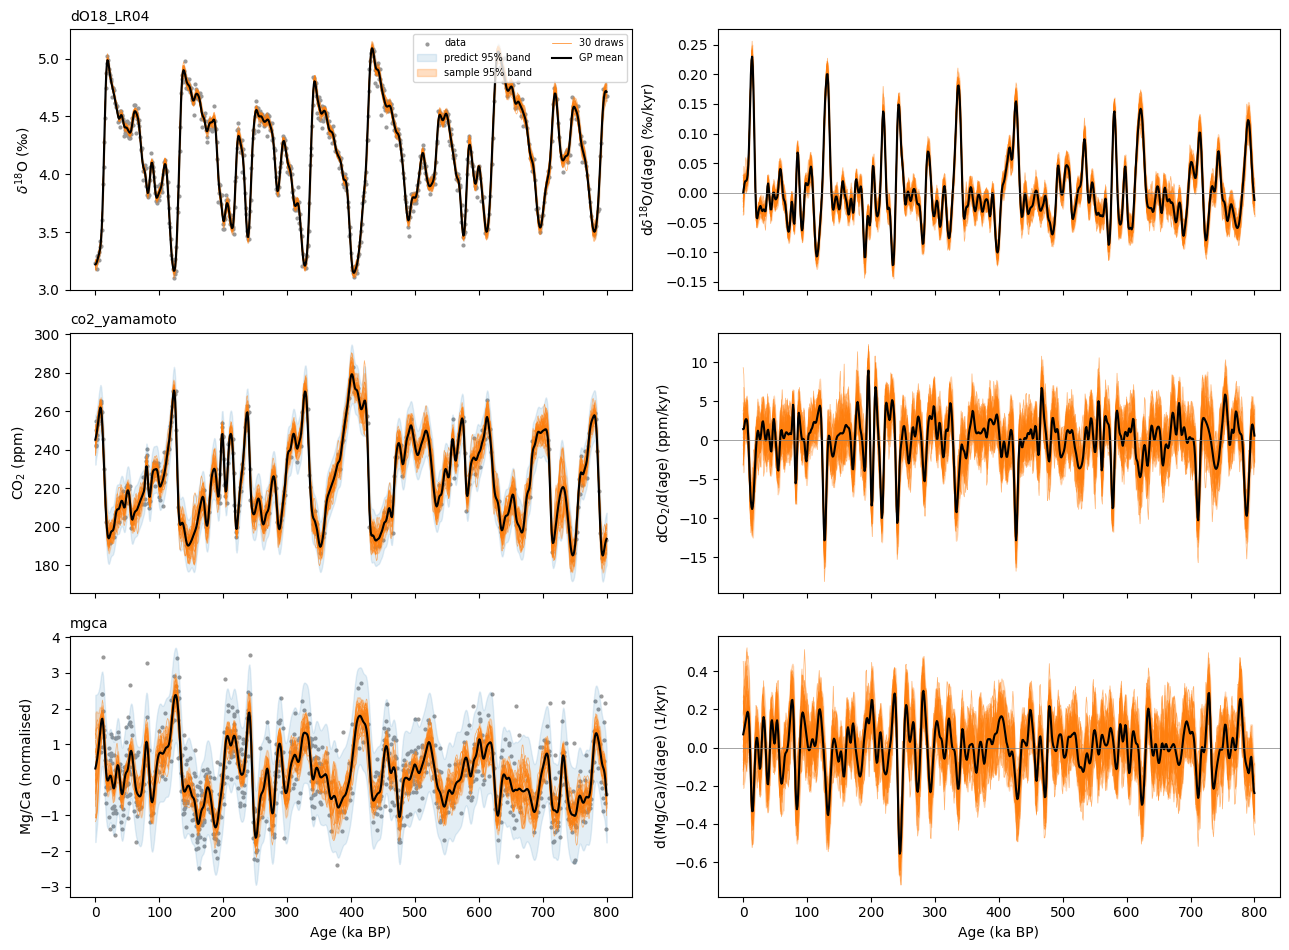

In [29]:
import matplotlib.pyplot as plt

n_show = 30          # trajectories drawn as spaghetti
tmax = 800           # kyr BP; None for the full grid

labels = {           # adjust units to your records
    "dO18_LR04":    (r"$\delta^{18}$O (‰)",  r"d$\delta^{18}$O/d(age) (‰/kyr)"),
    "co2_yamamoto": (r"CO$_2$ (ppm)",         r"dCO$_2$/d(age) (ppm/kyr)"),
    "mgca":         ("Mg/Ca (normalised)",    "d(Mg/Ca)/d(age) (1/kyr)"),
}

mask = tgrid <= tmax if tmax is not None else np.ones_like(tgrid, bool)
t = tgrid[mask]
idx = np.random.default_rng(0).choice(n_draws, n_show, replace=False)

fig, axes = plt.subplots(len(records), 2, figsize=(13, 3.2 * len(records)), sharex=True)

for row, (name, (gpr, X, y, mean_ref, std_ref, dot_ref)) in enumerate(records.items()):
    x_s    = samples[name]["x"][:, mask]
    xdot_s = samples[name]["xdot"][:, mask]
    m, s, d = (np.ravel(a)[mask] for a in (mean_ref, std_ref, dot_ref))
    ylab, dlab = labels[name]

    # --- state ---
    ax = axes[row, 0]
    in_win = X <= (tmax if tmax is not None else np.inf)
    ax.scatter(X[in_win], y[in_win], s=4, c="0.6", zorder=1, label="data")
    ax.fill_between(t, m - 1.96*s, m + 1.96*s, color="C0", alpha=0.12, label="predict 95% band")
    lo, hi = np.percentile(x_s, [2.5, 97.5], axis=0)
    ax.fill_between(t, lo, hi, color="C1", alpha=0.25, label="sample 95% band")
    ax.plot(t, x_s[idx].T, color="C1", lw=0.5, alpha=0.6)
    ax.plot([], [], color="C1", lw=0.5, label=f"{n_show} draws")
    ax.plot(t, m, color="k", lw=1.5, label="GP mean")
    ax.set_ylabel(ylab)
    ax.set_title(name, loc="left", fontsize=10)

    # --- derivative ---
    ax = axes[row, 1]
    lo, hi = np.percentile(xdot_s, [2.5, 97.5], axis=0)
    ax.fill_between(t, lo, hi, color="C1", alpha=0.25)
    ax.plot(t, xdot_s[idx].T, color="C1", lw=0.5, alpha=0.6)
    ax.plot(t, d, color="k", lw=1.5)
    ax.axhline(0, color="0.5", lw=0.5)
    ax.set_ylabel(dlab)

axes[0, 0].legend(loc="upper right", fontsize=7, ncol=2)
for ax in axes[-1]:
    ax.set_xlabel("Age (ka BP)")
fig.tight_layout()
plt.show()
# fig.savefig("gp_spaghetti.pdf", bbox_inches="tight")

In [30]:


order = ["dO18_LR04", "co2_yamamoto", "mgca"]
draw_cols = [f"draw_{i:03d}" for i in range(n_draws)]

for name in order:
    for kind in ("x", "xdot"):
        df = pd.DataFrame(samples[name][kind].T,          # (N, n_draws)
                          index=pd.Index(tgrid, name="age_ka"),
                          columns=draw_cols)
        df.to_csv(f"gp_draws_{name}_{kind}_1450.csv")